In [1]:
#!/usr/bin/env python
# coding: utf-8

# # Self supervised training

# In[661]:


# Standard library imports
import os
import sys
import random
import pickle
from pathlib import Path

# Third party imports
import numpy as np
import torch
from torch.utils.data import Dataset, TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Configure PyTorch settings
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Add project paths
models_path = Path().resolve().parents[1] / "src" / "models"
postproc_path = Path().resolve().parents[1] / "src" / "postprocessing"
sys.path.extend([str(models_path), str(postproc_path)])

# Import project modules
from trainDNN import *
from explainDNN import *
from predictDNN import *
from getModelPerformance import *


set_seed()
print(device)

# Load world features
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = sorted([f for f in dataset_path.iterdir() if f.is_file()])
features = np.load(files[0])
world_feature_shape_dim = features.shape[1]


#  Load input feature 
feature_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men/")
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]


if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")


Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)


cuda:0
Number of features: 110


In [2]:

import torch.nn.functional as F

class CombinedLoss(torch.nn.Module):
    def __init__(self, lambda_constraint):
        super(CombinedLoss, self).__init__()
        self.lambda_constraint = lambda_constraint
        self.MSELoss = torch.nn.MSELoss()
        self.L1Loss = torch.nn.L1Loss()

    def forward(self, features, labels, decoded, targets, porosity, train_step):


        constraint_loss = torch.mean(torch.clamp(targets * (porosity - 0.6), min=0))  # Hinge loss
        
        if train_step == 1:
            features = torch.reshape(features, (features.shape[0]*features.shape[1],1))
            decoded = torch.reshape(decoded, (decoded.shape[0]*decoded.shape[1],1))
            reconstruction_loss = self.MSELoss(features, decoded)  # Example: using L1 loss
            combined_loss = reconstruction_loss + self.lambda_constraint * constraint_loss
            
        elif train_step == 2:
            labels = torch.reshape(labels, (labels.shape[0],1))
            targets = torch.reshape(targets, (targets.shape[0],1))
            regression_loss = self.L1Loss(labels, targets)
            combined_loss = regression_loss + self.lambda_constraint * constraint_loss
            
        elif train_step == 3:
            features = torch.reshape(features, (features.shape[0]*features.shape[1],1))
            decoded = torch.reshape(decoded, (decoded.shape[0]*decoded.shape[1],1))
            labels = torch.reshape(labels, (labels.shape[0],1))
            targets = torch.reshape(targets, (targets.shape[0],1))
            regression_loss = self.L1Loss(labels, targets)
            reconstruction_loss = self.MSELoss(features, decoded)  # Example: using L1 loss
            combined_loss = reconstruction_loss + regression_loss + self.lambda_constraint * constraint_loss
            
        else:
            raise ValueError("Invalid train_step value.")
         
        return combined_loss

#loss_fn = CombinedLoss(lambda_constraint=0.5)#
#loss_fn = torch.nn.MSELoss()
loss_fn = torch.nn.HuberLoss()



In [3]:
# Load world features
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = sorted([f for f in dataset_path.iterdir() if f.is_file()])
features = np.load(files[0])
world_feature_shape_dim = features.shape[1]


#  Load input feature 
feature_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men/")
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]


if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")


features_DO, labels_DO, lats_DO, lons_DO = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)


from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_DO, q=n_bins, labels=False, duplicates='drop')
train_features_DO, train_labels_DO, test_features_DO, test_labels_DO = split_train_test_data(features_DO, labels_DO, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


# Load world features
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = sorted([f for f in dataset_path.iterdir() if f.is_file()])
features = np.load(files[0])
world_feature_shape_dim = features.shape[1]


#  Load input feature 
feature_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men/")
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]


if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")


features_CS, labels_CS, lats_CS, lons_CS = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)


from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_CS, q=n_bins, labels=False, duplicates='drop')
train_features_CS, train_labels_CS, test_features_CS, test_labels_CS = split_train_test_data(features_CS, labels_CS, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)

train_features = np.concatenate([train_features_CS, train_features_DO], axis = 0)
test_features = np.concatenate([test_features_CS, test_features_DO], axis = 0)
train_labels = np.concatenate([train_labels_CS, train_labels_DO], axis = 0)
test_labels = np.concatenate([test_labels_CS, test_labels_DO], axis = 0)
features = np.concatenate([features_CS, features_DO], axis = 0)
labels = np.concatenate([labels_CS, labels_DO], axis = 0)
batch_size = 64
trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


Number of features: 110
(7713,)
(7713,)
Number of rows in features before: 7713
Number of rows in features after: 6968
Number of rows in labels: 6968
Number of rows in lats: 6968
Number of rows in lons: 6968
Test size ratio
0.25
Number of features: 110
(10836,)
(10836,)
Number of rows in features before: 10836
Number of rows in features after: 6173
Number of rows in labels: 6173
Number of rows in lats: 6173
Number of rows in lons: 6173
Test size ratio
0.25
Train data size
9855
Test data size
3286


In [4]:
features_DO.shape

(6968, 110)

In [5]:

def enable_dropout(model):
    """ Function to enable the dropout layers during test-time """
    for m in model.modules():
        if m.__class__.__name__.startswith('Dropout'):
            m.train()


def get_predictions():
    #os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")


    from os import walk  
    feature_path = Path(Path() / "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men/")
    X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
    X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

    #dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
    dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
    files = []

    for (dirpath, dirnames, filenames) in walk(dataset_path):
        files.extend(filenames)
        break

    files.sort()


    features = np.load(Path(dataset_path / files[0]))
    #"""
    #model = FEA(layer_width)
    #model.load_state_dict(torch.load("/gxfs_work1/cau/sunms498/work/toc-neural-nets/SelectFeaturesRun/FEAmodel_test0_75.pth"))

    model.eval()
    enable_dropout(model) #for mc dropout

    chunk_shape = [6,4320] #360 chunks

    np.random.seed(42)
    torch.manual_seed(42)
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #'cuda:0' if torch.cuda.is_available() else 
    #print(physical_devices)
    model.to(device)
    print(device)
    model.double()


    #"""
    first_run = True
    ii = 0
    features = np.load(Path(dataset_path / files[0]))

    chunk_shape = [6,4320] #360 chunks


    first_run = True
    ii = 0

    for count, file in enumerate(files):
        features = np.load(Path(dataset_path / file))
        features = np.divide((features - X_mean), X_std)

        features = torch.tensor(features)
        features = features.to(device)

        # Perform multiple forward passes with dropout
        num_samples = 100  # Adjust this based on your requirements
        predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

        with torch.no_grad():
            for i in range(num_samples):
                predictions = model(features) #decoded, 
                #predictions = F.softmax(predictions, dim=1)  # If you're using softmax

                # Store predictions for later averaging
                predictions_sum[i] = predictions.cpu().detach().numpy().reshape(chunk_shape)

        # Average predictions over all samples
        predictions_avg = np.mean(predictions_sum, axis=0)
        predictions_var = np.var(predictions_sum, axis=0)

        if first_run:
            prediction_map2 = predictions_avg
            prediction_map2_var = predictions_var
            first_run = False
        else:
            prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
            prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

        ii += 1
        if ii == 359:
            print("Prediction " + str(ii) + " done!")

    #del features
    gc.collect()
    """    
    land_file = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/island_map.npy")
    land_map = np.load(land_file)
    land_map[np.isnan(land_map)] = 1
    #prediction_map2[land_map] = 0

    #plt.figure(figsize=[25,15], dpi=200)
    import matplotlib.colors as mcolors
    #prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
    plt.figure(figsize=[25, 15], dpi=50)
    #prediction_map2[land_map] = 0
    plt.imshow(prediction_map2, norm=mcolors.LogNorm(vmin=1e1, vmax=1e2),cmap="cubehelix")
    cbar = plt.colorbar()
    """


    np.save("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_SedRate_entire_supervised_"+str(layer_widths), prediction_map2)



In [6]:
layer_widths_all = [[512,256,128]]

In [7]:
train_features.shape

(9855, 110)

epoch: 0 | Training Loss: 60.540 | MAE: 61.008 | LR: 0.0080000 | count: 1/36 |
epoch: 0 | Testing Loss: 48.813 | MAE: 49.265 | count: 1/36 |
epoch: 1 | Training Loss: 48.194 | MAE: 48.650 | LR: 0.0040960 | count: 1/36 |
epoch: 1 | Testing Loss: 38.609 | MAE: 39.063 | count: 1/36 |
epoch: 2 | Training Loss: 42.799 | MAE: 43.254 | LR: 0.0026214 | count: 1/36 |
epoch: 2 | Testing Loss: 31.055 | MAE: 31.489 | count: 1/36 |
epoch: 3 | Training Loss: 38.984 | MAE: 39.440 | LR: 0.0013422 | count: 1/36 |
epoch: 3 | Testing Loss: 33.194 | MAE: 33.647 | count: 1/36 |
epoch: 4 | Training Loss: 37.401 | MAE: 37.853 | LR: 0.0006872 | count: 1/36 |
epoch: 4 | Testing Loss: 28.976 | MAE: 29.421 | count: 1/36 |
epoch: 5 | Training Loss: 35.742 | MAE: 36.194 | LR: 0.0003518 | count: 1/36 |
epoch: 5 | Testing Loss: 28.071 | MAE: 28.518 | count: 1/36 |
epoch: 6 | Training Loss: 35.049 | MAE: 35.501 | LR: 0.0001801 | count: 1/36 |
epoch: 6 | Testing Loss: 26.925 | MAE: 27.373 | count: 1/36 |
epoch: 7 | Tr

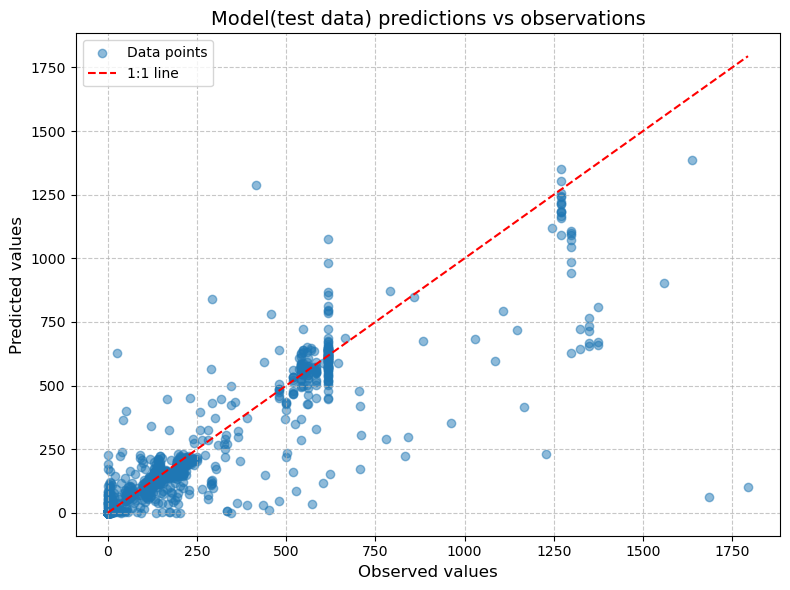

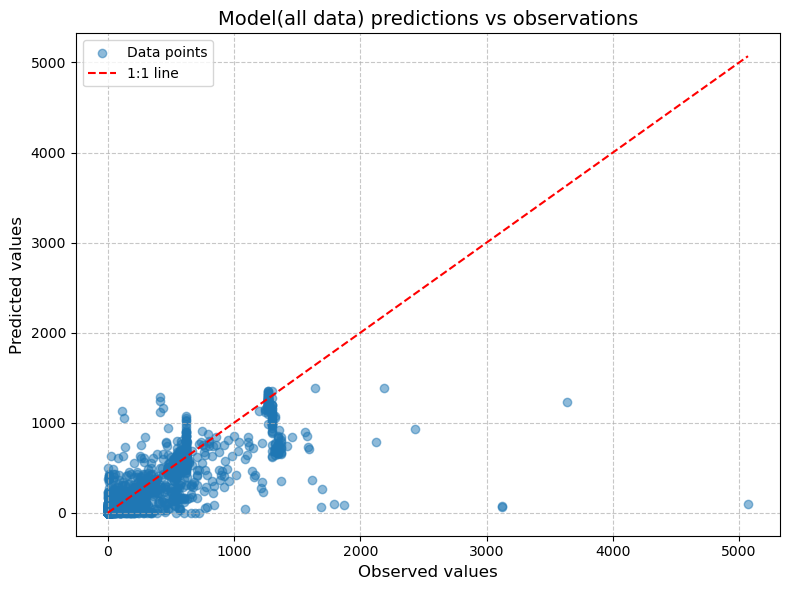

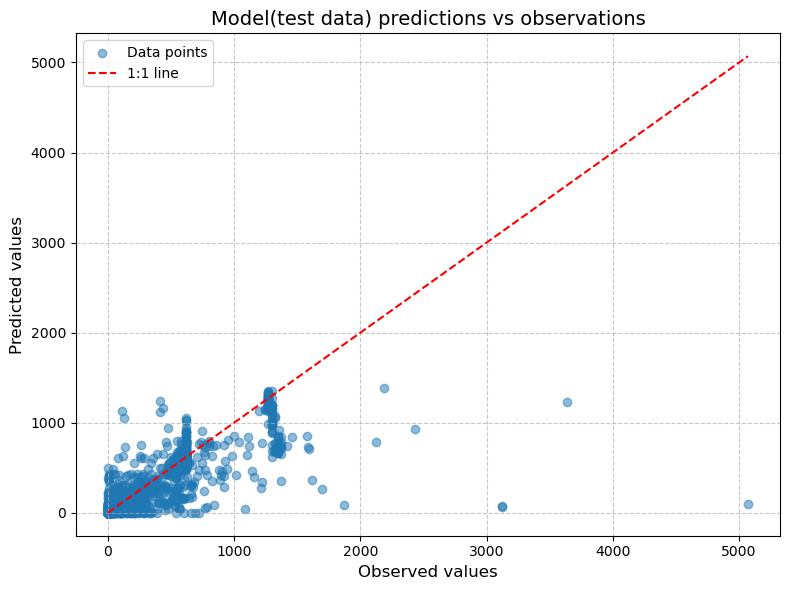

In [8]:
train_step = 2

#layer_widths_all = [[128]*10]
for layer_widths in layer_widths_all:
    set_seed(42)
    # Example usage:
    input_dim = features.shape[1]  # Replace with the actual input dimension
    # Define your desired layer widthsmodel = FEA(layer_widths)#FEA(input_dim, layer_widths)
    model = buildDNN(layer_widths, features)
    model.apply(initialize_weights)
    model.double()


    optimizer = torch.optim.Adam(model.parameters(),
                                 lr = 1e-3,
                                 weight_decay = 1e-8)

    lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.8, 
                                                              patience=50, threshold=0.0001, threshold_mode='rel', 
                                                              cooldown=0, min_lr=0.00001, eps=1e-08)#, verbose=False)


    reconstruction_loss_factor = 0
    target_loss_factor = 1
    count = 1



    if torch.cuda.is_available():
        model = model.cuda()
        loss_fn = loss_fn.cuda()

            
    num_epochs = 1800

    training_accuracy, training_losses, training_mae, learning_rate, evaluation_losses, evaluation_mae, true_labels, pred_labels =  train_model(model, loss_fn, trainloader, testloader, num_epochs = num_epochs)

    features = torch.tensor(features, dtype=torch.float64)
    labels = torch.tensor(labels, dtype=torch.float64)

    # Then move to GPU if available
    if torch.cuda.is_available():
        features = features.cuda()
        labels = labels.cuda()

    print("++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
    print("++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
    print("++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
    print("layer widths")
    print(layer_widths)
    print("evaluation losses")
    print(evaluation_mae[-5:])
    print("training loses")
    print(training_mae[-5:])
    output_path = "test_img"
    output_path = str(output_path)
    print("+++++++++test results+++++++++")
    test_labels, test_targets = evaluate_model(model, testloader, output_path)
    print("+++++++++all results+++++++++")
    all_labels, all_targets =  evaluate_all_predictions(model, features, labels, output_path)
    print("+++++++++train results+++++++++")
    train_labels, train_targets = evaluate_model(model, trainloader, output_path)    

    #get_predictions()





In [13]:
def collect_predictions_single(model, dataloader, device):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for features, labels in dataloader:
            features = torch.tensor(features, dtype=torch.double).to(device)
            labels = torch.tensor(labels, dtype=torch.double).to(device)

            outputs = model(features)   # <-- NO task argument

            y_true.append(labels)
            y_pred.append(outputs)

    y_true = torch.cat(y_true).reshape(-1).cpu().numpy()
    y_pred = torch.cat(y_pred).reshape(-1).cpu().numpy()

    return y_true, y_pred

In [14]:
def plot_predictions(y_train, train_preds, y_test, test_preds, model_name, n_estimators):
    # Calculate metrics
    train_mae = mean_absolute_error(y_train, train_preds)
    test_mae = mean_absolute_error(y_test, test_preds)
    train_corr = np.corrcoef(y_train, train_preds)[0, 1]
    test_corr = np.corrcoef(y_test, test_preds)[0, 1]

    # Combine train and test for density plot
    all_true = np.concatenate([y_train, y_test])
    all_pred = np.concatenate([train_preds, test_preds])

    # Find the overall min and max for axis and binning
    min_lim = min(all_true.min(), all_pred.min())
    max_lim = max(all_true.max(), all_pred.max())

    # Clamp display axis at 1500 as maximum
    min_display = min_lim
    max_display = min(1500, max_lim)

    plt.figure(figsize=(7, 7))

    # Use 2D histogram for density, limiting counts per bin to max 15
    counts, xedges, yedges, im = plt.hist2d(
        all_true, all_pred,
        bins=100,
        range=[[min_display, max_display], [min_display, max_display]],
        cmap='viridis',
        cmin=0, vmax=15
    )
    # Set up colorbar and annotate with ">15" for max value
    cbar = plt.colorbar(im)
    cbar.set_label('Counts', fontsize=12)
    
    # Generate the colorbar ticks up to 15
    cbar_ticks = np.arange(0, 16, 3)
    if cbar_ticks[-1] != 15:
        cbar_ticks = np.append(cbar_ticks, 15)
    cbar.set_ticks(cbar_ticks)
    ticklabels = [f"{int(t)}" for t in cbar_ticks]
    if len(ticklabels) > 0:
        ticklabels[-1] = ">15"
    cbar.set_ticklabels(ticklabels)

    # Set specified grid values at 300, 600, 1200, 1500
    grid_values = [300, 600, 900, 1200, 1500]
    plt.xlim(min_display, max_display)
    plt.ylim(min_display, max_display)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_xticks(grid_values)
    plt.gca().set_yticks(grid_values)

    plt.plot([min_display, max_display], [min_display, max_display], 'k--', lw=2)
    plt.xlabel('True Values')
    plt.ylabel('Predicted Values')
    #plt.title(f"{model_name} Predictions (n_estimators={n_estimators:.0f})")

    # Place the statistics in a textbox - LEFT TOP CORNER (x,y = 0.05, 0.85)
    textstr = (
        f"Train MAE: {train_mae:.3f}, CC: {train_corr:.3f}\n"
        f"Test MAE: {test_mae:.3f}, CC: {test_corr:.3f}"
    )
    plt.gcf().text(0.15, 0.80, textstr, fontsize=10, bbox=dict(facecolor='white', alpha=0.5), ha='left', va='top')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


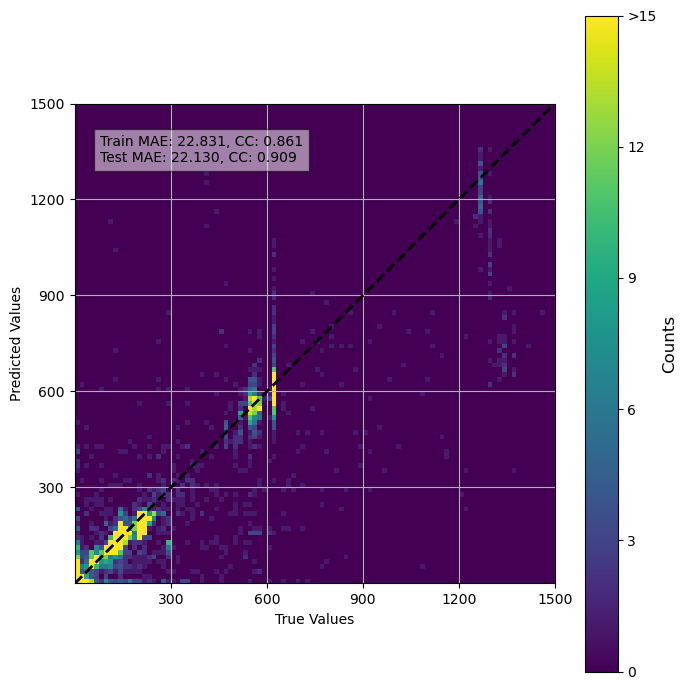

In [15]:
y_train, train_preds = collect_predictions_single(model, trainloader, device)
y_test, test_preds   = collect_predictions_single(model, testloader, device)

plot_predictions(
    y_train=y_train,
    train_preds=train_preds,
    y_test=y_test,
    test_preds=test_preds,
    model_name="Single-task Model",
    n_estimators=0  # dummy value
)


In [9]:
from os import walk  
feature_path = Path(Path() / "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men/")
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()


features = np.load(Path(dataset_path / files[0]))
#"""
#model = FEA(layer_width)
#model.load_state_dict(torch.load("/gxfs_work1/cau/sunms498/work/toc-neural-nets/SelectFeaturesRun/FEAmodel_test0_75.pth"))

model.eval()
enable_dropout(model) #for mc dropout

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #'cuda:0' if torch.cuda.is_available() else 
#print(physical_devices)
model.to(device)
print(device)
model.double()


#"""
first_run = True
ii = 0
features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks


first_run = True
ii = 0

for count, file in enumerate(files):
    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)

    features = torch.tensor(features)
    features = features.to(device)

    # Perform multiple forward passes with dropout
    num_samples = 100  # Adjust this based on your requirements
    predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    with torch.no_grad():
        for i in range(num_samples):
            predictions = model(features) #decoded, 
            #predictions = F.softmax(predictions, dim=1)  # If you're using softmax

            # Store predictions for later averaging
            predictions_sum[i] = predictions.cpu().detach().numpy().reshape(chunk_shape)

    # Average predictions over all samples
    predictions_avg = np.mean(predictions_sum, axis=0)
    predictions_var = np.var(predictions_sum, axis=0)

    if first_run:
        prediction_map2 = predictions_avg
        prediction_map2_var = predictions_var
        first_run = False
    else:
        prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
        prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

    ii += 1
    if ii == 359:
        print("Prediction " + str(ii) + " done!")

#del features
gc.collect()

cuda:0
Prediction 359 done!


7441

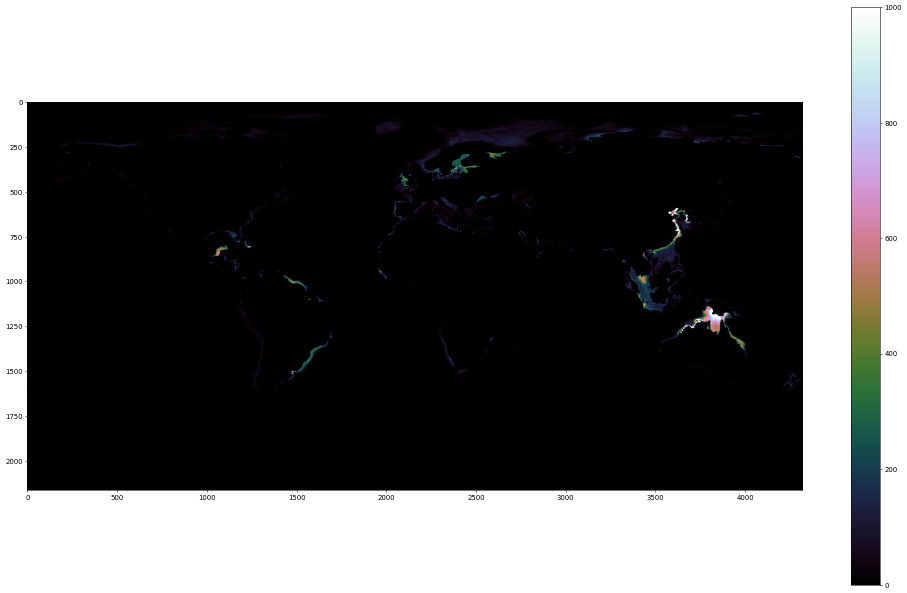

In [10]:
land_file = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/island_map.npy")
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
prediction_map2[land_map] = 0
plt.imshow(prediction_map2, vmin = 0, vmax = 1000,cmap="cubehelix")
cbar = plt.colorbar()

In [11]:
np.save("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_SedRate_entire_nn_n2", prediction_map2)